# Imports

In [36]:
# Imports
import string
from tensorflow.keras.applications.inception_v3 import InceptionV3
from tensorflow.keras.models import Model

from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.inception_v3 import preprocess_input
import numpy as np
import os
import pickle

from tensorflow.keras.layers import Input, Dense, LSTM, Embedding, Dropout
from tensorflow.keras.layers import add

from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import to_categorical
from numpy import array
import matplotlib.pyplot as plt

# 5. Understanding the Data

In [37]:
# Below is the path for the file "Flickr8k.token.txt" on your disk
filename = "/Users/briccs/Desktop/Flickr_8k_Text/Flickr_8k.token.txt"
file = open(filename, 'r')
doc = file.read()

In [38]:
descriptions = dict()
for line in doc.split('\n'):
    # split line by white space
    tokens = line.split()
    
    if len(tokens) < 2: # Added to skip empty lines
        continue

    # take the first token as image id, the rest as description
    image_id, image_desc = tokens[0], tokens[1:]
    
    # extract filename from image id
    image_id = image_id.split('.')[0]
    
    # convert description tokens back to string
    image_desc = ' '.join(image_desc)
    if image_id not in descriptions:
        descriptions[image_id] = list()
    descriptions[image_id].append(image_desc)

# 6. Data Cleaning

In [39]:
# prepare translation table for removing punctuation
table = str.maketrans('', '', string.punctuation)
for key, desc_list in descriptions.items():
    for i in range(len(desc_list)):
        desc = desc_list[i]
        # tokenize
        desc = desc.split()
        # convert to lower case
        desc = [word.lower() for word in desc]
        # remove punctuation from each token
        desc = [w.translate(table) for w in desc]
        # remove hanging 's' and 'a'
        desc = [word for word in desc if len(word)>1]
        # remove tokens with numbers in them
        desc = [word for word in desc if word.isalpha()]
        # store as string
        desc_list[i] =  ' '.join(desc)

In [40]:
vocabulary = set()
for key in descriptions.keys():
    [vocabulary.update(d.split()) for d in descriptions[key]]
print('Original Vocabulary Size: %d' % len(vocabulary))

Original Vocabulary Size: 8763


In [41]:
train_descriptions = descriptions # Fix issue
# Create a list of all the training captions
all_train_captions = []
for key, val in train_descriptions.items():
    for cap in val:
        all_train_captions.append(cap)

# Consider only words which occur at least 10 times in the corpus
word_count_threshold = 10
word_counts = {}
nsents = 0
for sent in all_train_captions:
    nsents += 1
    for w in sent.split(' '):
        word_counts[w] = word_counts.get(w, 0) + 1

vocab = [w for w in word_counts if word_counts[w] >= word_count_threshold]

print('preprocessed words %d ' % len(vocab))
# preprocessed words 1651

preprocessed words 1947 


# 7. Loading the Training Set

In [42]:
filename = '/Users/briccs/Desktop/Flickr_8k_Text/Flickr_8k.trainImages.txt'
with open(filename, 'r') as file: # Copied version from above
    doc = file.read()
train = set() # Changed from list to set
for line in doc.split('\n'):
    identifier = line.split('.')[0]
    train.add(identifier)
print('Dataset: %d' % len(train))

Dataset: 6001


In [43]:
def save_descriptions(descriptions, filename):
    lines = []
    for key, desc_list in descriptions.items():
        for desc in desc_list:
            lines.append(key + ' ' + desc)
    data = '\n'.join(lines)
    with open(filename, 'w') as file:
        file.write(data)

# Save the file
save_descriptions(descriptions, '/Users/briccs/Desktop/Flickr_8k_Text/descriptions.txt')

In [44]:
# load clean descriptions and keep only training-image captions
desc_file = '/Users/briccs/Desktop/Flickr_8k_Text/descriptions.txt'
with open(desc_file, 'r') as file:
    doc = file.read()

train_descriptions = dict()

for line in doc.split('\n'):
    tokens = line.split()

    if len(tokens) < 2:
        continue

    image_id, image_desc = tokens[0], tokens[1:]

    if image_id in train:
        if image_id not in train_descriptions:
            train_descriptions[image_id] = list()

        desc = 'startseq ' + ' '.join(image_desc) + ' endseq'
        train_descriptions[image_id].append(desc)

print('Descriptions: train=%d' % len(train_descriptions))

Descriptions: train=6000


# 8. Data Preprocessing — Images

In [45]:
# Get the InceptionV3 model trained on imagenet data
model = InceptionV3(weights='imagenet')
# Remove the last layer (output softmax layer) from the inception v3
model_new = Model(model.input, model.layers[-2].output)

In [46]:
# Folder containing Flickr8k images
images_dir = '/Users/briccs/Desktop/Flickr_8k_Images'

# Dictionary to store features
encoding_train = {}

# Loop through all image files
for img_name in os.listdir(images_dir):
    if not img_name.lower().endswith('.jpg'):
        continue

    img_path = os.path.join(images_dir, img_name)

    # Load and preprocess image
    img = image.load_img(img_path, target_size=(299, 299))
    x = image.img_to_array(img)
    x = np.expand_dims(x, axis=0)
    x = preprocess_input(x)

    # Extract feature vector
    feature = model_new.predict(x, verbose=0)
    feature = np.reshape(feature, feature.shape[1])

    # Remove .jpg from key to match caption IDs
    image_id = img_name.split('.')[0]
    encoding_train[image_id] = feature

print('Encoded Images:', len(encoding_train))

# Save features to disk
with open('/Users/briccs/Desktop/Flickr_8k_Text/encoded_train_images.pkl', 'wb') as file:
    pickle.dump(encoding_train, file)

Encoded Images: 8091


# 9. Data Preprocessing — Captions

In [47]:
ixtoword = {}
wordtoix = {}

ix = 1
for w in vocab:
    wordtoix[w] = ix
    ixtoword[ix] = w
    ix += 1

In [48]:
# convert a dictionary of clean descriptions to a list of descriptions
def to_lines(descriptions):
 all_desc = list()
 for key in descriptions.keys():
  [all_desc.append(d) for d in descriptions[key]]
 return all_desc
# calculate the length of the description with the most words
def max_length(descriptions):
 lines = to_lines(descriptions)
 return max(len(d.split()) for d in lines)
# determine the maximum sequence length
max_length = max_length(train_descriptions)
print('Max Description Length: %d' % max_length)

Max Description Length: 34


# 10. Data Peparation Using Generator Function

In [57]:
from numpy import array

def data_generator(descriptions, photos, wordtoix, max_length, num_photos_per_batch):
    X1, X2, y = [], [], []
    n = 0

    while True:
        for key, desc_list in descriptions.items():
            n += 1
            photo = photos[key]   # no '.jpg'

            for desc in desc_list:
                seq = [wordtoix[word] for word in desc.split(' ') if word in wordtoix]

                for i in range(1, len(seq)):
                    in_seq, out_seq = seq[:i], seq[i]

                    in_seq = pad_sequences([in_seq], maxlen=max_length)[0]
                    out_seq = to_categorical([out_seq], num_classes=vocab_size)[0]

                    X1.append(photo)
                    X2.append(in_seq)
                    y.append(out_seq)

            if n == num_photos_per_batch:
                yield ((array(X1), array(X2)), array(y))
                X1, X2, y = [], [], []
                n = 0

# 11. Word Embeddings

In [58]:
# Load Glove vectors
glove_dir = '/Users/briccs/Desktop/Flickr_8k_Text/glove/'
embeddings_index = {} # empty dictionary
f = open(os.path.join(glove_dir, 'glove.6B.200d.txt'), encoding="utf-8")
for line in f:
    values = line.split()
    word = values[0]
    coefs = np.asarray(values[1:], dtype='float32')
    embeddings_index[word] = coefs
f.close()

# 12. Model Architecture

In [59]:
vocab_size = len(ixtoword) + 1
embedding_dim = 200

# Get 200-dim dense vector for each of the 10000 words in out vocabulary
embedding_matrix = np.zeros((vocab_size, embedding_dim))

for word, i in wordtoix.items():
    #if i < max_words:
    embedding_vector = embeddings_index.get(word)
    if embedding_vector is not None:
        # Words not found in the embedding index will be all zeros
        embedding_matrix[i] = embedding_vector

embedding_matrix.shape

(1948, 200)

In [60]:
inputs1 = Input(shape=(2048,))
fe1 = Dropout(0.5)(inputs1)
fe2 = Dense(256, activation='relu')(fe1)

inputs2 = Input(shape=(max_length,))
se1 = Embedding(vocab_size, embedding_dim, mask_zero=True)(inputs2)
se2 = Dropout(0.5)(se1)
se3 = LSTM(256)(se2)

decoder1 = add([fe2, se3])
decoder2 = Dense(256, activation='relu')(decoder1)
outputs = Dense(vocab_size, activation='softmax')(decoder2)

model = Model(inputs=[inputs1, inputs2], outputs=outputs)

model.layers[2].set_weights([embedding_matrix])
model.layers[2].trainable = False

model.compile(loss='categorical_crossentropy', optimizer='adam')

In [ ]:
os.makedirs('./model_weights', exist_ok=True)

epochs = 10
number_pics_per_batch = 3
steps = len(train_descriptions) // number_pics_per_batch

for i in range(epochs):
    generator = data_generator(
        train_descriptions,
        encoding_train,
        wordtoix,
        max_length,
        number_pics_per_batch
    )
    model.fit(generator, epochs=1, steps_per_epoch=steps, verbose=1)
    model.save('./model_weights/model_' + str(i) + '.h5')

2000/2000 ━━━━━━━━━━━━━━━━━━━━ 234s 116ms/step - loss: 4.4800


2000/2000 ━━━━━━━━━━━━━━━━━━━━ 228s 114ms/step - loss: 3.6770


2000/2000 ━━━━━━━━━━━━━━━━━━━━ 228s 114ms/step - loss: 3.4286


2000/2000 ━━━━━━━━━━━━━━━━━━━━ 227s 113ms/step - loss: 3.2716


2000/2000 ━━━━━━━━━━━━━━━━━━━━ 227s 113ms/step - loss: 3.1573


2000/2000 ━━━━━━━━━━━━━━━━━━━━ 237s 119ms/step - loss: 3.0680


2000/2000 ━━━━━━━━━━━━━━━━━━━━ 247s 123ms/step - loss: 2.9942


2000/2000 ━━━━━━━━━━━━━━━━━━━━ 251s 125ms/step - loss: 2.9363


2000/2000 ━━━━━━━━━━━━━━━━━━━━ 244s 122ms/step - loss: 2.8881


2000/2000 ━━━━━━━━━━━━━━━━━━━━ 236s 118ms/step - loss: 2.8445


SyntaxError: 'yield' outside function (1540430022.py, line 18)

# 13. Inference

In [62]:
def greedySearch(photo):
    in_text = 'startseq'
    for i in range(max_length):
        sequence = [wordtoix[w] for w in in_text.split() if w in wordtoix]
        sequence = pad_sequences([sequence], maxlen=max_length)
        yhat = model.predict([photo, sequence], verbose=0)
        yhat = np.argmax(yhat)
        word = ixtoword.get(yhat)
        if word is None:
            break
        in_text += ' ' + word
        if word == 'endseq':
            break
    final = in_text.split()
    final = final[1:-1]
    return ' '.join(final)

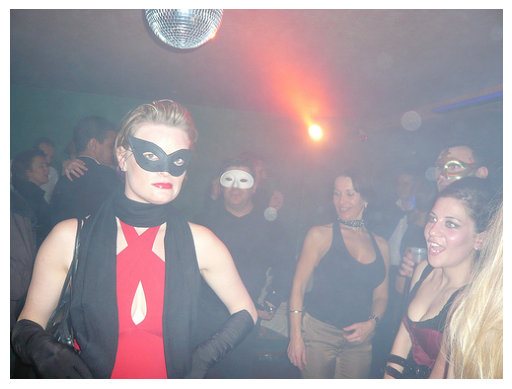

Greedy: shopping cart with man in red shirt and hat is sitting on the ground next to large machine machine while another man looks on the ground next to her friend who is sitting


In [63]:
sample_id = list(encoding_train.keys())[0]
sample_feature = encoding_train[sample_id].reshape((1, 2048))

img_path = os.path.join(images_dir, sample_id + '.jpg')
x = plt.imread(img_path)
plt.imshow(x)
plt.axis('off')
plt.show()

print("Greedy:", greedySearch(sample_feature))